# Tarea 05: Cálculo simbólico

**Semana 5** · Entrega: antes de la clase de la Semana 6

## Objetivos de la tarea

1. Derivar una expresión simbólica y usar la derivada para localizar un
   equilibrio con `solve`.
2. Resolver una ecuación diferencial con `dsolve` imponiendo condiciones
   iniciales.
3. Extraer el caso límite de una solución con `limit`, cuando sustituir
   no basta.

In [1]:
import sympy as sp

sp.init_printing()

## Ejercicio 1 (caso base)

El **potencial de Lennard-Jones** describe la interacción entre dos átomos
neutros:

$$V(r) = 4\varepsilon\left[\left(\frac{\sigma}{r}\right)^{12}
- \left(\frac{\sigma}{r}\right)^{6}\right]$$

El término repulsivo domina de cerca y el atractivo de lejos, así que hay
una distancia de equilibrio entre ambos. Vas a encontrarla derivando.

Completa la celda con estos nombres exactos, que son los que usa
`tests/test_tarea.py`:

- `distancia`, `epsilon` y `sigma`: los tres símbolos. Sus **nombres de
  símbolo** deben ser `"r"`, `"epsilon"` y `"sigma"` (no los de las
  variables de Python, como vimos en la semana 4). Los tres son
  **positivos**: una distancia, una energía de enlace y una escala de
  longitud.
- `potencial`: la expresión de $V(r)$.
- `fuerza`: la fuerza $F = -dV/dr$, con `sp.diff`.
- `distancia_equilibrio`: la distancia donde la fuerza se anula, obtenida
  **con `sp.solve`** (no escrita a mano). Como `solve` devuelve una lista,
  quédate con su único elemento. Debe salirte $2^{1/6}\sigma$.
- `energia_minima`: el valor del potencial en esa distancia, obtenido con
  `subs` y simplificado. Debe salirte $-\varepsilon$ — de ahí el nombre del
  parámetro: $\varepsilon$ es la profundidad del pozo.
- `curvatura`: la segunda derivada del potencial evaluada en el equilibrio,
  simplificada. Es la constante elástica efectiva de las oscilaciones
  pequeñas de la molécula, la misma idea del TODO 1 de la sesión 1.

Las suposiciones importan aquí más que en la tarea pasada: con
`distancia` positiva, `solve` devuelve **una** solución. Sin suposiciones
devuelve las doce raíces complejas del polinomio, y el ejercicio se vuelve
otro.

Ejercicio 1: Hasta la parte de la fuerza

In [2]:
# TODO: completa el ejercicio 1

#Primero, definimos los nombres de nuestros símbolos
distancia =sp.Symbol("r", positive=True )
epsilon =sp.Symbol("epsilon", positive=True)
sigma =sp.Symbol("sigma", positive=True)

#Luego, definimos el potencial
potencial=4*epsilon*((sigma/distancia)**12-(sigma/distancia)**6)

#después, vamos a definir a la fuerza, esta va a estar dada por -dv/dx
fuerza =-sp.diff(potencial, distancia) 

In [ ]:
#Verificamos los símbolos
print(distancia)
print(epsilon)
print(sigma)

r
epsilon
sigma


In [8]:
#Imprimimos la expresión dle potencial
print(potencial)

4*epsilon*(-sigma**6/r**6 + sigma**12/r**12)


In [9]:
print(fuerza)

-4*epsilon*(6*sigma**6/r**7 - 12*sigma**12/r**13)


Ejercicio 1: Segunda parte

In [4]:
#Ahora, vamos a usar solve para definir la distancia de equilibrio
distancia_equilibrio =sp.solve(fuerza, distancia)

#En esta parte, definimos ahora la energía mínima, que es el valor del potencial en la distancia de equilibrio
#como es una lista, accedemos a su único elemento usando los índices: [0]
energia_minima =potencial.subs(distancia, distancia_equilibrio[0])


#Finalmente, definimos la curvatura, que es la segunda derivada del potencial
segunda_potencial=sp.diff(potencial, distancia, 2)
curvatura =segunda_potencial.subs(distancia, distancia_equilibrio[0])

In [10]:
#Imprimimos la expresión de la distancia en equilibrio
distancia_equilibrio

In [11]:
#Verificamos el término de la energía mínima
#comprobamos la salida de la energía mínima
energia_minima

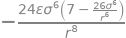

In [12]:
#verificamos la segunda derivada del potencial
segunda_potencial

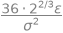

In [13]:
curvatura

## Ejercicio 2 (caso límite)

Un oscilador armónico de frecuencia propia $\omega$ es empujado por una
fuerza que oscila con **otra** frecuencia, $\Omega$:

$$m\,\ddot{x} = -m\omega^2 x + F_0 \cos(\Omega t),
\qquad x(0) = 0, \quad \dot{x}(0) = 0$$

La solución existe para cualquier par de frecuencias distintas. La pregunta
interesante es qué pasa cuando la fuerza se sintoniza con el oscilador,
$\Omega \to \omega$: ahí el denominador de la solución se anula, y hay que
tomar un **límite** para ver qué queda. Eso es la resonancia.

Completa la celda con estos nombres:

- `tiempo`, `masa`, `frecuencia_propia`, `frecuencia_forzamiento` y
  `fuerza_maxima`: los símbolos, con nombres `"t"`, `"m"`, `"omega"`,
  `"Omega"` y `"F_0"`. Los cinco son **positivos**.
- `posicion`: la función incógnita, `sp.Function("x")`.
- `ecuacion_forzada`: la ecuación de movimiento, escrita con `sp.Eq`.
- `solucion_forzada`: el resultado de `sp.dsolve` con las dos condiciones
  iniciales en `ics` (parte del reposo, desde el origen). Recuerda cómo se
  escribe la condición sobre la derivada: `posicion(tiempo).diff(tiempo).subs(tiempo, 0)`.
  Es una `Eq`, no una expresión.
- `movimiento`: solo la expresión de $x(t)$, es decir el `.rhs` de la
  solución.
- `movimiento_en_resonancia`: el límite de `movimiento` cuando
  `frecuencia_forzamiento` tiende a `frecuencia_propia`, con `sp.limit`.
  Ojo: el límite es **sobre la frecuencia**, no sobre el tiempo.

Cuando lo tengas, mira `movimiento_en_resonancia` y responde en una celda
de markdown, en dos o tres renglones: ¿por qué la amplitud crece sin
límite, y qué le falta a este modelo para describir un sistema real? La
respuesta corta a lo segundo cabe en una palabra, y es algo que el modelo
no incluye.

Un aviso: la forma exacta en que SymPy escriba la solución **no** tiene por
qué coincidir con la de tu compañero. Los tests comparan equivalencia
simbólica, no cadenas, así que cualquier forma correcta se da por buena.

In [ ]:
# TODO: completa el ejercicio 2
#Ejercicio 2: Primero, definimos las variables
tiempo =sp.Symbol("t", positive=True)
masa =sp.Symbol("m", positive=True)
frecuencia_propia = sp.Symbol("omega", positive=True)
frecuencia_forzamiento = sp.Symbol("Omega", positive=True)
fuerza_maxima = sp.Symbol("F_0", positive=True)

#Definimos a la posición
posicion =sp.Function("x")


#Definimos la ecuación de movimiento
ecuacion_forzada =sp.Eq(masa*posicion(tiempo).diff(tiempo, 2), -masa*frecuencia_propia**2 * posicion(tiempo)+fuerza_maxima*sp.cos(frecuencia_forzamiento*tiempo))


In [31]:
#Definimos la solución forzada
solucion_forzada =sp.dsolve(
    ecuacion_forzada,
    posicion(tiempo),
    ics={
        posicion(0):0,
        posicion(tiempo).diff(tiempo).subs(tiempo, 0): 0,
        },
)


#definimos la ecuación de movimiento
movimiento =solucion_forzada.rhs

#Finalmente, definimos el movimiento en resonancia
movimiento_en_resonancia =sp.limit(movimiento, frecuencia_forzamiento, frecuencia_propia)

In [17]:
#Imprimimos los símbolos
print(tiempo)
print(masa)
print(frecuencia_propia)
print(frecuencia_forzamiento)
print(fuerza_maxima)

t
m
omega
Omega
F_0


In [19]:
#Imprimimos a la posicion
posicion

x

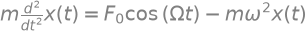

In [22]:
#Comprobamos cuál es la expresión que define a la ecuación forzada
ecuacion_forzada

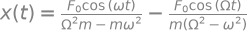

In [ ]:
#Imprimimos la funcion forzada
solucion_forzada

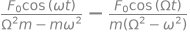

In [30]:
movimiento

In [32]:
movimiento_en_resonancia

La amplitud crece sin límite porque la frecuencia propia del sistema y la frecuencia de la fuerza externa se sincronizan, esto tiene entonces como consecuencia, que la amplitud del movimiento aumente indefinidamente porque la energía del oscilador se mantiene en aumento.

Este modelo omite la parte del amortiguamiento (como por ejemplo, la fricción con el aire), lo que en un caso más realista, evitaría que la amplitud creciera al infinito, haciendo que el oscilador se fuera estabilizando en una amplitud máxima constante.

## Resumen

Entrega esta tarea por **Pull Request dentro de tu fork**, como la de la
semana 4. El paso a paso está en
[`docs/git-guia.md`](../../docs/git-guia.md), y el checklist completo en
[`README.md`](README.md).

Antes de entregar, corre el notebook desde un kernel limpio
(`Kernel → Restart & Run All`) y confirma que llega hasta el final sin
errores. Al hacer push, GitHub Actions corre los tests y deja un check
✅ o ❌ en tu Pull Request.